
# Business Insights and Recommendations

## Business Objective

The Customer Intelligence Platform aims to help an e-commerce business better understand customer purchasing behaviour, distinguish customer segments, and identify opportunities to improve repeat purchasing and customer value.

This notebook translates the platform's validated analytical outputs into business insights and recommendations.

## Business Problem

Not all customers contribute equally to business performance.

Some customers make larger initial purchases, while others have a greater likelihood of purchasing again. Focusing on only one of these characteristics can lead to incomplete conclusions about customer value.

The business needs to understand:

- How frequently customers make a repeat purchase.
- How observed merchandise value differs across customer segments.
- Whether predicted repeat-purchase propensity helps distinguish historical purchasing behaviour.
- Which customer groups could be considered for targeted retention experiments.
- How to evaluate whether proposed interventions create measurable incremental value.

## Key Business Questions

1. What is the observed baseline for repeat purchasing and customer value?
2. How do purchasing behaviour and value differ across customer segments?
3. What opportunities emerge when repeat-purchase propensity and initial purchase value are considered together?
4. Which recommendations are supported by the evidence?
5. What experiments and performance measures are needed before broader business adoption?

## Analytical Approach

The analysis uses the validated customer-level reporting dataset produced in Notebook 11.

The dataset contains 78,100 customers and combines:

- Customer purchasing information.
- Predicted repeat-purchase propensity.
- Existing customer segmentation.
- First-order delivery status.
- Observed 60-day merchandise value.

Recommendations will distinguish established historical findings from hypotheses requiring experimental validation.

## Important Boundaries

- Observed merchandise value is not profit or customer lifetime value.
- Repeat-purchase propensity is not a prediction of monetary value.
- Historical segment differences do not establish causal effects.
- The dataset includes observations previously used in model development and evaluation; results are not independent prospective validation.
- Business recommendations must be supported by evidence and accompanied by measurable success criteria.


## Customer Performance Baseline

Establish the overall repeat-purchase rate and observed merchandise
value using the validated customer reporting dataset from Notebook 11.

This provides a consistent reference point for subsequent segment
comparisons and business recommendations.

In [1]:

# Load the validated customer reporting dataset
# Confirm that the population and monetary outcomes match Notebook 11

from pathlib import Path
import pandas as pd
import numpy as np

project_root = Path.cwd().parent
processed_dir = project_root / "data" / "processed"

customer_reporting = pd.read_parquet(
    processed_dir / "customer_intelligence_reporting.parquet"
)

# Verify the customer population and reporting schema
assert len(customer_reporting) == 78_100
assert customer_reporting.shape[1] == 14
assert customer_reporting["customer_unique_id"].is_unique
assert customer_reporting["customer_unique_id"].notna().all()

# Verify the observed outcomes against the validated historical totals
assert customer_reporting["repeat_purchase_60d"].sum() == 1_589

assert np.isclose(
    customer_reporting["initial_delivered_value"].sum(),
    10_395_105.68,
    atol=0.01
)

assert np.isclose(
    customer_reporting["subsequent_60d_value"].sum(),
    211_295.19,
    atol=0.01
)

assert np.isclose(
    customer_reporting["total_60d_merchandise_value"].sum(),
    10_606_400.87,
    atol=0.01
)

print("VALIDATED CUSTOMER REPORTING DATASET LOADED")
print(f"Customers: {len(customer_reporting):,}")
print(f"Columns: {customer_reporting.shape[1]}")
print("Customer uniqueness: PASSED")
print("Historical monetary reconciliation: PASSED")


VALIDATED CUSTOMER REPORTING DATASET LOADED
Customers: 78,100
Columns: 14
Customer uniqueness: PASSED
Historical monetary reconciliation: PASSED


In [2]:

# Establish the overall customer performance baseline
# Use observed outcomes rather than model predictions

total_customers = len(customer_reporting)

repeat_purchasers = int(
    customer_reporting["repeat_purchase_60d"].sum()
)

repeat_purchase_rate = repeat_purchasers / total_customers

initial_value = customer_reporting["initial_delivered_value"].sum()
subsequent_value = customer_reporting["subsequent_60d_value"].sum()
total_value = customer_reporting["total_60d_merchandise_value"].sum()

average_total_value = total_value / total_customers
average_subsequent_value = subsequent_value / total_customers
subsequent_value_share = subsequent_value / total_value

customer_baseline = pd.DataFrame({
    "Business metric": [
        "Customers evaluated",
        "Customers with repeat purchases",
        "Observed 60-day repeat-purchase rate (%)",
        "Initial delivered merchandise value (R$)",
        "Subsequent 60-day merchandise value (R$)",
        "Total observed 60-day merchandise value (R$)",
        "Average observed value per customer (R$)",
        "Average subsequent value per customer (R$)",
        "Subsequent purchase contribution (%)"
    ],
    "Value": [
        total_customers,
        repeat_purchasers,
        round(100 * repeat_purchase_rate, 2),
        round(initial_value, 2),
        round(subsequent_value, 2),
        round(total_value, 2),
        round(average_total_value, 2),
        round(average_subsequent_value, 2),
        round(100 * subsequent_value_share, 2)
    ]
})

print("CUSTOMER PERFORMANCE BASELINE")
display(customer_baseline)

# Reconcile the total value and customer outcomes
assert np.isclose(initial_value + subsequent_value, total_value)
assert repeat_purchasers == 1_589

print("\nCustomer performance baseline reconciled successfully.")


CUSTOMER PERFORMANCE BASELINE


,Business metric,Value
0,Customers evaluated,78100.00
1,Customers with repeat purchases,1589.00
2,Observed 60-day repeat-purchase rate (%),2.03
3,Initial delivered merchandise value (R$),10395105.68
4,Subsequent 60-day merchandise value (R$),211295.19
5,Total observed 60-day merchandise value (R$),10606400.87
6,Average observed value per customer (R$),135.81
7,Average subsequent value per customer (R$),2.71
8,Subsequent purchase contribution (%),1.99



Customer performance baseline reconciled successfully.


## Customer Segments and Retention Opportunities

Compare customer profiles against the overall repeat-purchase
baseline to identify differences in observed customer behaviour.

Segment differences are descriptive and will be used to generate
hypotheses, not to claim that targeting will increase revenue.

In [3]:

# Compare customer profiles against the observed repeat-purchase baseline
# Include customer population, monetary value, and repeat-rate lift

customer_opportunity_summary = (
    customer_reporting
    .groupby("customer_profile", dropna=False)
    .agg(
        customers=("customer_unique_id", "count"),
        repeat_purchasers=("repeat_purchase_60d", "sum"),
        repeat_rate=("repeat_purchase_60d", "mean"),
        total_subsequent_value=("subsequent_60d_value", "sum"),
        average_subsequent_value=("subsequent_60d_value", "mean"),
        average_60d_value=("total_60d_merchandise_value", "mean")
    )
    .reset_index()
)

# Compare each profile with the overall customer baseline
customer_opportunity_summary["repeat_rate_pct"] = (
    customer_opportunity_summary["repeat_rate"] * 100
)

customer_opportunity_summary["repeat_rate_lift"] = (
    customer_opportunity_summary["repeat_rate"] / repeat_purchase_rate
)

customer_opportunity_summary["customer_share_pct"] = (
    100 * customer_opportunity_summary["customers"] / total_customers
)

customer_opportunity_summary["subsequent_value_share_pct"] = (
    100
    * customer_opportunity_summary["total_subsequent_value"]
    / subsequent_value
)

# Display highest historical repeat-purchase rates first
customer_opportunity_summary = (
    customer_opportunity_summary
    .sort_values("repeat_rate", ascending=False)
    .reset_index(drop=True)
)

print("CUSTOMER PROFILE PERFORMANCE AGAINST BUSINESS BASELINE")
print(f"Overall repeat-purchase baseline: {repeat_purchase_rate:.2%}")

display(
    customer_opportunity_summary[
        [
            "customer_profile",
            "customers",
            "customer_share_pct",
            "repeat_purchasers",
            "repeat_rate_pct",
            "repeat_rate_lift",
            "average_subsequent_value",
            "average_60d_value",
            "subsequent_value_share_pct"
        ]
    ].round(2)
)

# Confirm the summary reconciles to the validated dataset
assert customer_opportunity_summary["customers"].sum() == 78_100
assert customer_opportunity_summary["repeat_purchasers"].sum() == 1_589

assert np.isclose(
    customer_opportunity_summary["total_subsequent_value"].sum(),
    211_295.19,
    atol=0.01
)

print("\nCustomer opportunity summary reconciled successfully.")


CUSTOMER PROFILE PERFORMANCE AGAINST BUSINESS BASELINE
Overall repeat-purchase baseline: 2.03%


,customer_profile,customers,customer_share_pct,repeat_purchasers,repeat_rate_pct,repeat_rate_lift,average_subsequent_value,average_60d_value,subsequent_value_share_pct
0,Lower Value | High Propensity,7814,10.01,284,3.63,1.79,2.92,52.66,10.80
1,Higher Value | High Propensity,7287,9.33,259,3.55,1.75,5.58,175.70,19.23
2,Unknown Initial Value,642,0.82,21,3.27,1.61,6.33,6.33,1.92
3,Lower Value | Medium Propensity,12766,16.35,282,2.21,1.09,2.06,47.03,12.47
4,Higher Value | Medium Propensity,10543,13.50,209,1.98,0.97,3.02,186.28,15.08
5,Lower Value | Low Propensity,18117,23.20,285,1.57,0.77,1.54,44.96,13.23
6,Higher Value | Low Propensity,20931,26.80,249,1.19,0.58,2.75,264.28,27.27



Customer opportunity summary reconciled successfully.


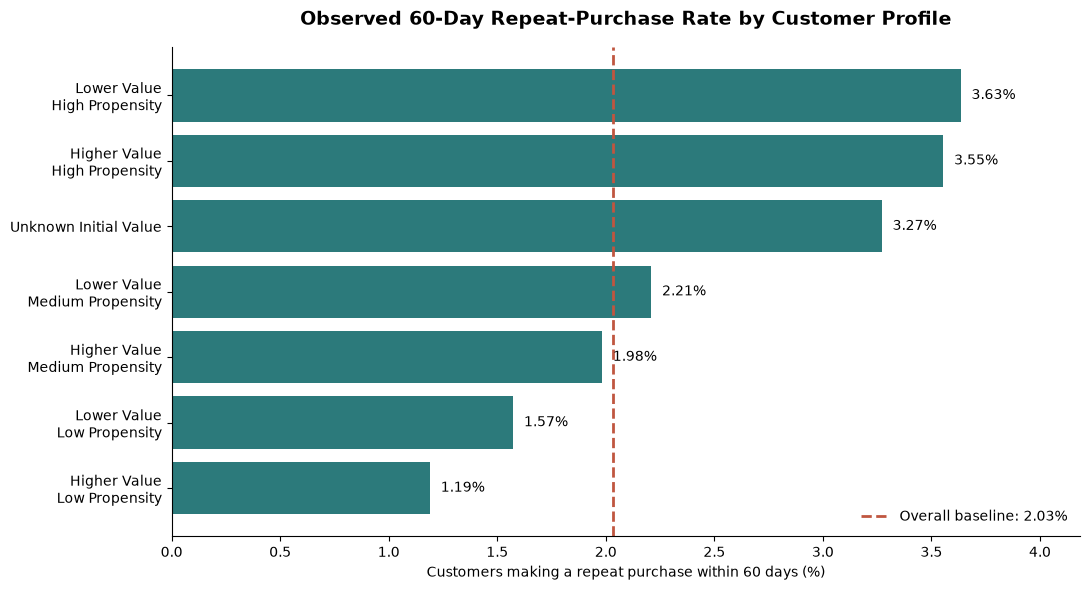

In [4]:

# Visualise observed repeat-purchase rates across customer profiles
# Compare each profile against the overall customer baseline

import matplotlib.pyplot as plt

plot_data = customer_opportunity_summary.sort_values(
    "repeat_rate_pct",
    ascending=True
).copy()

# Format profile names for more readable chart labels
plot_data["profile_label"] = (
    plot_data["customer_profile"]
    .str.replace(" | ", "\n", regex=False)
)

fig, ax = plt.subplots(figsize=(11, 6))

bars = ax.barh(
    plot_data["profile_label"],
    plot_data["repeat_rate_pct"],
    color="#2C7A7B"
)

# Add the population-wide reference point
ax.axvline(
    x=100 * repeat_purchase_rate,
    color="#C05640",
    linestyle="--",
    linewidth=2,
    label=f"Overall baseline: {repeat_purchase_rate:.2%}"
)

# Show observed percentages beside each bar
for bar in bars:
    ax.text(
        bar.get_width() + 0.05,
        bar.get_y() + bar.get_height() / 2,
        f"{bar.get_width():.2f}%",
        va="center",
        fontsize=10
    )

ax.set_title(
    "Observed 60-Day Repeat-Purchase Rate by Customer Profile",
    fontsize=14,
    fontweight="bold",
    pad=16
)

ax.set_xlabel("Customers making a repeat purchase within 60 days (%)")
ax.set_ylabel("")

ax.set_xlim(0, plot_data["repeat_rate_pct"].max() + 0.55)

ax.legend(loc="lower right", frameon=False)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()


In [5]:
## Opportunity Assessment: Customer Scale and Observed Value

# Assess customer profiles using population size and observed value
# This is a descriptive opportunity assessment, not an uplift forecast

opportunity_assessment = customer_opportunity_summary[
    [
        "customer_profile",
        "customers",
        "customer_share_pct",
        "repeat_rate_pct",
        "average_subsequent_value",
        "average_60d_value",
        "total_subsequent_value",
        "subsequent_value_share_pct"
    ]
].copy()

# Add observed non-repeat customer counts for audience sizing
opportunity_assessment["customers_without_repeat_purchase"] = (
    opportunity_assessment["customers"]
    - customer_opportunity_summary["repeat_purchasers"]
)

# Display profiles with the largest populations first
opportunity_assessment = opportunity_assessment.sort_values(
    "customers",
    ascending=False
).reset_index(drop=True)

print("CUSTOMER OPPORTUNITY ASSESSMENT")
display(opportunity_assessment.round(2))

# Reconcile the audience counts
assert opportunity_assessment["customers"].sum() == total_customers

assert (
    opportunity_assessment["customers_without_repeat_purchase"].sum()
    == total_customers - repeat_purchasers
)

assert np.isclose(
    opportunity_assessment["total_subsequent_value"].sum(),
    subsequent_value
)

print("\nOpportunity assessment reconciled successfully.")


CUSTOMER OPPORTUNITY ASSESSMENT


,customer_profile,customers,customer_share_pct,repeat_rate_pct,average_subsequent_value,average_60d_value,total_subsequent_value,subsequent_value_share_pct,customers_without_repeat_purchase
0,Higher Value | Low Propensity,20931,26.80,1.19,2.75,264.28,57619.49,27.27,20682
1,Lower Value | Low Propensity,18117,23.20,1.57,1.54,44.96,27958.22,13.23,17832
2,Lower Value | Medium Propensity,12766,16.35,2.21,2.06,47.03,26342.29,12.47,12484
3,Higher Value | Medium Propensity,10543,13.50,1.98,3.02,186.28,31855.87,15.08,10334
4,Lower Value | High Propensity,7814,10.01,3.63,2.92,52.66,22825.82,10.80,7530
5,Higher Value | High Propensity,7287,9.33,3.55,5.58,175.70,40631.07,19.23,7028
6,Unknown Initial Value,642,0.82,3.27,6.33,6.33,4062.43,1.92,621



Opportunity assessment reconciled successfully.



## Business Opportunity Hypotheses

The opportunity assessment identifies three customer groups for further investigation. These are hypotheses for experimentation, not established intervention effects.

### Hypothesis A: Retention barriers among higher-value, low-propensity customers

**Evidence:** This is the largest customer profile, containing 20,931 customers (26.80% of the population). Its average observed 60-day merchandise value is R$264.28, while its repeat-purchase rate is 1.19%.

**Business question:** Can an appropriately timed post-purchase intervention increase repeat purchasing among customers with relatively high initial basket values?

**Proposed investigation:** Examine purchase categories, customer experience, purchase timing, and potential reasons for non-repeat purchasing. Use these findings to design a controlled retention experiment.

**Success criteria:** Incremental delivered repeat-purchase rate, incremental merchandise value, and contribution margin after intervention costs.

### Hypothesis B: Incremental value among higher-value, high-propensity customers

**Evidence:** This group contains 7,287 customers and has an observed repeat-purchase rate of 3.55%. Its average subsequent merchandise value is R$5.58 per customer.

**Business question:** Does additional engagement create incremental purchases, or would these customers purchase again without intervention?

**Proposed investigation:** Test a low-cost post-purchase engagement strategy against a randomly assigned control group.

**Success criteria:** Incremental repeat purchasing and contribution margin relative to the control group.

### Hypothesis C: Commercial efficiency among lower-value, low-propensity customers

**Evidence:** This group contains 18,117 customers, with an observed repeat-purchase rate of 1.57% and average observed 60-day merchandise value of R$44.96.

**Business question:** Can inexpensive engagement improve repeat purchasing sufficiently to justify its cost?

**Proposed investigation:** Evaluate low-cost communication channels before considering financial incentives.

**Success criteria:** Incremental contribution margin per eligible customer and cost per incremental repeat purchaser.

### Decision Principles

- Segment size indicates potential reach, not expected incremental value.
- Historical repeat-purchase rates describe observed behaviour, not customer responsiveness to treatment.
- Customers must be eligible and classified using information available before intervention.
- Randomised controls should be used to measure incremental impact.
- Recommendations should account for intervention costs, margin, and operational feasibility.
- The Unknown Initial Value group should be treated separately because its initial basket-value feature is missing.

### Proposed Initial Priority

Investigate the Higher Value | Low Propensity segment first because it combines substantial population size, high observed initial merchandise value, and relatively low historical repeat purchasing.

This is a priority for discovery and experiment design, not a recommendation for immediate campaign deployment.



## Proposed Retention Experiment

### Business Decision

Should the business introduce a targeted post-purchase retention intervention for higher-initial-value customers with low predicted repeat-purchase propensity?

The objective is to establish whether the intervention produces incremental repeat purchases and sufficient commercial value to justify its cost.

### Evidence Supporting the Investigation

The Higher Value | Low Propensity profile contains:

- 20,931 customers, representing 26.80% of the historical population.
- An observed 60-day repeat-purchase rate of 1.19%.
- Average observed 60-day merchandise value of R$264.28.
- R$57,619.49 in subsequent merchandise value across the profile.

These historical results justify further investigation. They do not establish that the proposed intervention will succeed.

### Experiment Hypothesis

A relevant, timely post-purchase engagement intervention will increase the probability of a second delivered purchase within 60 days compared with receiving no additional experiment-specific engagement.

### Eligible Population

Include customers who:

- Have completed a qualifying first purchase.
- Have a recorded initial basket value.
- Are classified as Higher Value | Low Propensity using information available at the decision point.
- Have not already made a qualifying subsequent purchase before assignment.
- Meet applicable marketing consent and contact eligibility requirements.

Exclude customers whose first recorded orders were canceled, unavailable, or otherwise not eligible for the defined post-purchase journey.

### Experiment Design

**Assignment:** Randomly allocate eligible customers to treatment and control groups at the customer level.

**Treatment group:** Receive a clearly defined post-purchase engagement intervention, such as a relevant product reminder or personalised recommendation.

**Control group:** Continue receiving the existing customer experience without the additional experiment-specific intervention.

**Measurement window:** Observe delivered repeat purchases within 60 days of the qualifying first purchase.

**Randomisation:** Assign customers before the intervention and retain their original assignment for analysis.

**Analysis principle:** Evaluate outcomes according to original randomised assignment, including customers who do not engage with the intervention.

### Primary Success Metric

**Incremental 60-day delivered repeat-purchase rate**

Compare the proportion of customers making a qualifying repeat purchase between treatment and control groups.

### Commercial Success Metrics

- Incremental subsequent delivered merchandise value per assigned customer.
- Incremental contribution margin after intervention costs.
- Cost per incremental repeat purchaser.

The business should not approve scaling based solely on engagement or click-through rates.

### Guardrail Metrics

- Unsubscribe and complaint rates.
- Contact frequency and customer experience.
- Returns, refunds, and cancellations where data is available.
- Promotion and communication costs.
- Data quality and outcome-measurement completeness.

### Decision Criteria

**Scale:** Consider broader rollout only if the experiment shows credible incremental commercial benefit, acceptable customer-experience outcomes, and a positive contribution-margin case.

**Iterate:** Revise the proposition, timing, or eligible population if results are inconclusive or operational issues affect interpretation.

**Stop:** Do not scale if incremental contribution is negative or customer-experience guardrails deteriorate materially.

### Limitations and Prerequisites

- The existing analysis does not contain treatment or control outcomes.
- Incremental revenue and customer responsiveness cannot currently be estimated reliably.
- A sample-size calculation requires an agreed minimum detectable effect, statistical power, and significance threshold.
- Contribution-margin measurement requires cost inputs beyond merchandise value.
- The propensity model and segmentation rules must be available and appropriate at the intervention decision point.
- A historical 60-day evaluation window must not be confused with longer-term customer retention or lifetime value.


## Experiment Feasibility and Sample-Size Scenarios

Estimate the sample sizes required for a two-group randomised
retention experiment using the observed repeat-purchase rate
as a historical planning baseline.

The calculations illustrate feasibility under assumed treatment
effects. They do not predict the effectiveness of an intervention.

The final sample-size decision requires agreement on the minimum
commercially meaningful effect, statistical power, significance
level, and anticipated eligible customer volume.

In [9]:

# Estimate sample size for a two-group randomised experiment
# Assumptions are illustrative and do not represent predicted uplift

from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize

# Use the exact observed repeat rate for the proposed customer profile
target_profile = customer_reporting.loc[
    customer_reporting["customer_profile"].eq(
        "Higher Value | Low Propensity"
    )
]

baseline_rate = target_profile["repeat_purchase_60d"].mean()

assert len(target_profile) == 20_931
assert target_profile["repeat_purchase_60d"].sum() == 249

# Conventional planning assumptions, subject to business agreement
significance_level = 0.05
statistical_power = 0.80

# Illustrative relative improvements in repeat-purchase probability
relative_uplift_scenarios = [0.10, 0.20, 0.30, 0.50]

power_analysis = NormalIndPower()

sample_size_results = []

for relative_uplift in relative_uplift_scenarios:
    treatment_rate = baseline_rate * (1 + relative_uplift)

    effect_size = abs(
        proportion_effectsize(baseline_rate, treatment_rate)
    )

    customers_per_group = int(
        np.ceil(
            power_analysis.solve_power(
                effect_size=effect_size,
                alpha=significance_level,
                power=statistical_power,
                ratio=1.0,
                alternative="two-sided"
            )
        )
    )

    sample_size_results.append({
        "assumed_relative_uplift_pct": relative_uplift * 100,
        "baseline_repeat_rate_pct": baseline_rate * 100,
        "assumed_treatment_rate_pct": treatment_rate * 100,
        "absolute_improvement_pp": (
            treatment_rate - baseline_rate
        ) * 100,
        "customers_per_group": customers_per_group,
        "total_customers_required": customers_per_group * 2
    })

experiment_sample_sizes = pd.DataFrame(sample_size_results)

print("ILLUSTRATIVE RETENTION EXPERIMENT SAMPLE SIZES")
print(f"Historical baseline: {baseline_rate:.3%}")
print(f"Statistical power: {statistical_power:.0%}")
print(f"Significance level: {significance_level:.0%}")
print("Allocation: 50% treatment / 50% control")

display(experiment_sample_sizes.round(3))

print(
    "\nThese sample sizes are planning scenarios, "
    "not forecasts of intervention effectiveness."
)


ILLUSTRATIVE RETENTION EXPERIMENT SAMPLE SIZES
Historical baseline: 1.190%
Statistical power: 80%
Significance level: 5%
Allocation: 50% treatment / 50% control


,assumed_relative_uplift_pct,baseline_repeat_rate_pct,assumed_treatment_rate_pct,absolute_improvement_pp,customers_per_group,total_customers_required
0,10.0,1.19,1.309,0.119,136746,273492
1,20.0,1.19,1.428,0.238,35740,71480
2,30.0,1.19,1.547,0.357,16560,33120
3,50.0,1.19,1.784,0.595,6435,12870



These sample sizes are planning scenarios, not forecasts of intervention effectiveness.



## Experiment Feasibility Assessment

### Historical Baseline

The Higher Value | Low Propensity segment contains 20,931 customers, of whom 249 made a qualifying repeat purchase within 60 days.

The observed repeat-purchase rate is approximately 1.19%.

### Sample-Size Findings

Assuming a two-sided statistical test, 5% significance level, 80% power, and equal treatment/control allocation:

| Assumed Relative Improvement | Total Customers Required |
|---|---:|
| 10% | 273,492 |
| 20% | 71,480 |
| 30% | 33,120 |
| 50% | 12,870 |

These improvements are hypothetical planning scenarios, not predictions of intervention effectiveness.

### Business Implications

The historical target population is smaller than the required sample sizes for assumed relative improvements of 10%, 20%, and 30%.

A 50% assumed relative improvement would require approximately 12,870 customers, but there is no evidence that such an effect is achievable.

Historical segment size does not establish future experiment eligibility or recruitment volume.

The low baseline repeat-purchase rate creates a substantial measurement challenge for detecting modest improvements.

### Recommendation

Do not proceed directly to a large-scale targeted retention campaign.

First:

1. Investigate the causes of low repeat purchasing.
2. Estimate the weekly flow of newly eligible customers.
3. Establish the minimum commercially meaningful effect using contribution-margin assumptions.
4. Confirm the availability of reliable, pre-intervention propensity scores.
5. Reassess experiment feasibility before approving a randomised effectiveness test.

If a small operational pilot is conducted, evaluate delivery feasibility and customer experience without treating an underpowered outcome comparison as proof of incremental impact.

### Decision

**Status: Further discovery required before experiment approval.**

The customer segment remains commercially interesting, but the available evidence does not yet support immediate campaign deployment or an effectiveness claim.



## Final Business Recommendations and Decision Framework

### Executive Assessment

The Customer Intelligence Platform provides a validated view of purchasing behaviour, predicted repeat-purchase propensity, and observed merchandise value across 78,100 customers.

The analysis identifies meaningful differences in historical repeat purchasing and customer value. However, these differences do not establish which customers would respond positively to an intervention.

The principal recommendation is to use the platform to improve customer understanding and experiment planning before committing to large-scale targeted retention activity.

### Recommendation 1: Establish a Consistent Customer Performance Scorecard

**Decision: Proceed with descriptive reporting.**

Use the validated reporting dataset to monitor:

- Observed 60-day repeat-purchase rate.
- Initial delivered merchandise value.
- Subsequent 60-day merchandise value.
- Average observed merchandise value per customer.
- Customer distribution across propensity and value segments.
- First-order delivery outcomes and missing-value classifications.

The historical baseline is a 2.03% repeat-purchase rate and R$10.61 million in observed 60-day merchandise value.

**Business benefit:** A consistent foundation for understanding customer behaviour and comparing customer groups.

**Important condition:** Clearly distinguish observed merchandise value from revenue, profit, and customer lifetime value.

### Recommendation 2: Investigate High-Initial-Value Customers with Low Repeat Propensity

**Decision: Prioritise discovery, not immediate campaign deployment.**

This segment contains 20,931 customers and has an observed repeat-purchase rate of 1.19%.

Its average observed 60-day merchandise value is R$264.28, the highest among the customer profiles.

Investigate:

- Differences in product categories and purchasing patterns.
- Potential barriers to a subsequent purchase.
- Customer experience and delivery outcomes.
- Typical repurchase intervals.
- Whether relevant engagement opportunities exist.

**Business benefit:** Better understanding of a commercially significant customer population.

**Decision gate:** Do not approve a targeted effectiveness experiment until eligibility, intervention design, commercial value, and recruitment feasibility are established.

### Recommendation 3: Validate Whether Targeted Engagement Creates Incremental Value

**Decision: Experiment only when measurement is feasible.**

Historical propensity segments distinguish repeat-purchase behaviour, but the analysis does not establish incremental treatment responsiveness.

A controlled experiment should measure:

- Incremental delivered repeat-purchase rate.
- Incremental subsequent merchandise value per assigned customer.
- Contribution margin after intervention costs.
- Customer experience and communication guardrails.

The sample-size assessment shows that modest improvements may require substantially larger populations than the historical target segment.

**Business benefit:** Avoid allocating retention spend based solely on observational correlations.

**Decision gate:** Require a commercially meaningful effect definition, sufficient eligible customer volume, and a credible measurement plan.

### Recommendation 4: Strengthen Predictive Reliability Before Operational Deployment

**Decision: Continue validation before automated targeting.**

The repeat-purchase model provides a useful analytical segmentation signal, but the existing integrated analysis includes customers previously used in model development and evaluation.

Before operational deployment:

- Confirm that scoring features are available at the intervention decision point.
- Validate performance on genuinely future customer cohorts.
- Monitor model discrimination and probability calibration.
- Evaluate stability across time and relevant customer groups.
- Confirm that model-driven decisions outperform appropriate business benchmarks.

Experimental monetary-value predictions should remain outside the main reporting dataset until independently validated.

**Business benefit:** Reduce the risk of unreliable targeting decisions and unsupported claims about customer value.

### Recommendation 5: Preserve Transparent Data Definitions

**Decision: Proceed with documented data-quality safeguards.**

Maintain the distinction between:

- Recorded first-order basket value.
- Observed initial delivered merchandise value.
- Observed subsequent 60-day merchandise value.
- Predicted repeat-purchase propensity.

The integrated dataset includes 2,501 customers whose first recorded orders were not delivered, including 642 with missing first-order basket values.

Retain these observations and their existing classifications rather than silently excluding or replacing them.

**Business benefit:** Improve interpretability, reproducibility, and stakeholder confidence.

## Decision Summary

| Proposed Action | Decision | Evidence Required Next |
|---|---|---|
| Descriptive customer scorecard | Proceed | Reporting quality assurance and stakeholder sign-off |
| Investigate higher-value, low-propensity customers | Prioritise discovery | Behavioural and customer-experience evidence |
| Launch targeted retention effectiveness experiment | Conditional | Eligibility, commercial assumptions, sample-size feasibility |
| Deploy propensity-driven automated targeting | Not yet approved | Prospective model and operational validation |
| Deploy predicted monetary customer value | Not yet approved | Independent predictive and commercial validation |
| Preserve validated customer definitions | Proceed | Ongoing data-quality monitoring |

## Final Business Conclusion

The platform demonstrates that customer purchasing behaviour and observed merchandise value should be considered together rather than treated as interchangeable measures.

The immediate business opportunity is to establish trusted customer reporting and improve the quality of retention decisions.

The evidence supports targeted investigation and rigorous experiment planning. It does not currently support claims that propensity-based campaigns will increase incremental revenue or profitability.

The recommended approach is to move from descriptive customer intelligence to controlled, commercially measurable decision-making.
